# Módulo 1 — Acondicionamiento

| | |
|---|---|
| **Responde** | ítems 4 y 5 |
| **Código** | `acondicionamiento.py` (en esta misma carpeta) |
| **Recibe** | la señal cruda y `fs` |
| **Devuelve** | la señal acondicionada: misma cantidad de muestras y sin corrimiento en el tiempo |
| **Responsable** | _completar_ |

> Las funciones se programan en `acondicionamiento.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: correr `python main.py` desde la carpeta del repo.

In [11]:
# --- Configuración del cuaderno ---

# El cuaderno está en modulos/m1_acondicionamiento/. Agregando "../.." (la raíz
# del repo) a la ruta de búsqueda, Python encuentra el paquete "modulos".
import sys
sys.path.insert(0, "../..")

# autoreload: si se edita acondicionamiento.py, los cambios se toman solos al
# correr la próxima celda, sin reiniciar el kernel.
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m0_carga_de_datos.carga_de_datos import Registro   # "caja" con ecg, fs, voluntario...
from modulos.m1_acondicionamiento import acondicionamiento as acond   # nuestro módulo, abreviado "acond"
from modulos.herramientas import graficos   # estilo común de figuras y guardar_figura()

# Mientras lista_de_registros.csv esté vacía, M0 avisa con un warning por cada
# fila. Se silencia sólo ese aviso para que no ensucie la salida.
import warnings
warnings.filterwarnings("ignore", message=".*falta el nombre del archivo.*")

# Tamaño de letra, grilla, etc. iguales en todas las figuras del informe
graficos.aplicar_estilo()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Registros

Se cargan con `carga_de_datos.cargar_todos()`. Mientras M0 no esté terminado (o `lista_de_registros.csv` esté vacía), la celda lee los CSV directamente con la frecuencia de muestreo del informe (sección 2.2). **Cuando M0 esté listo, esta celda usa M0 sola y el bloque provisorio deja de correr.**

In [12]:
# --- Carga de los registros ---

# Primero se intenta la carga "oficial" a través de M0.
# Si M0 no está programado (NotImplementedError) o la lista está vacía,
# "registros" queda vacío y se usa el bloque provisorio de abajo.
try:
    registros = carga_de_datos.cargar_todos()
except NotImplementedError:
    registros = []

if not registros:   # --- provisorio, hasta que M0 esté listo ---
    # OJO: la fs no se lee del archivo (no tiene columna de tiempo).
    # Si se confirma otro valor, cambiarlo acá y en M0, y volver a correr todo.
    FS_PROVISORIA = 250.0   # Hz, la de la sección 2.2 del informe

    # (archivo, voluntario, condición). Se asume que los dos son de V1.
    provisorios = [("Copia de ecg_data_pre.csv", "V1", "reposo"),
                   ("Copia de ecg_data_post.csv", "V1", "post_ejercicio")]
    for archivo, vol, cond in provisorios:
        # El CSV tiene una sola columna, "Sample", con la tensión en voltios
        ecg = pd.read_csv(carga_de_datos.CARPETA_REGISTROS_CRUDOS / archivo)["Sample"].to_numpy(float)
        registros.append(Registro(ecg=ecg, fs=FS_PROVISORIA, voluntario=vol, condicion=cond,
                                  archivo=archivo, unidades="V"))

# Resumen de lo cargado. duración = muestras / fs (depende de que fs sea correcta)
for reg in registros:
    print(f"{reg.nombre:20s} {len(reg.ecg):6d} muestras  fs = {reg.fs:.0f} Hz  "
          f"duración = {reg.duracion:6.1f} s  rango = {reg.ecg.min():.2f} a {reg.ecg.max():.2f} {reg.unidades}")

V1_reposo             28800 muestras  fs = 250 Hz  duración =  115.2 s  rango = 1.28 a 3.03 V
V1_post_ejercicio     86600 muestras  fs = 250 Hz  duración =  346.4 s  rango = 0.00 a 3.30 V


## Ítem 4 — ¿Hace falta acondicionar? Ruidos asociados al registro

Evidencia de cada defecto del registro descrito en la sección 2.3 del informe.

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/Trabajos Practicos/Informe-Laboratorio-ECG---PSIB---Grupo-2-/informe/figuras/acond_crudo_completo.pdf')

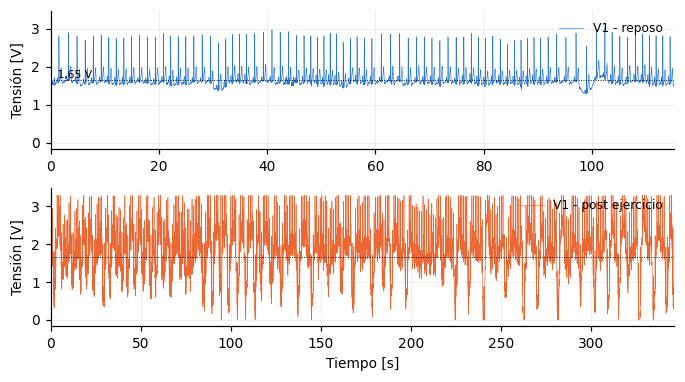

In [13]:
# --- Figura: registros crudos completos ---
# Muestra el nivel de continua (todo montado sobre 1,65 V), la deriva de la
# línea de base y la saturación (en el post ejercicio llega a 0 V y a 3,3 V).

# Un subgráfico por registro, uno debajo del otro, con el mismo eje y.
# 16/2.54 pasa 16 cm a pulgadas (16 cm = ancho del texto en el informe).
fig, axs = plt.subplots(len(registros), 1, figsize=(16/2.54, 4.5*len(registros)/2.54), sharey=True)
axs = np.atleast_1d(axs)   # para que funcione igual si hubiera un solo registro

for ax, reg in zip(axs, registros):
    # Eje de tiempo: número de muestra / fs
    t = np.arange(len(reg.ecg)) / reg.fs
    # estilo_registro da color según la condición y tipo de línea según el voluntario
    ax.plot(t, reg.ecg, lw=0.4, **graficos.estilo_registro(reg.voluntario, reg.condicion))
    ax.axhline(1.65, color="k", lw=0.6, ls=":")   # referencia de la placa (Vcc/2)
    ax.set(ylabel="Tensión [V]", xlim=(0, t[-1]))
    ax.legend(loc="upper right")
# Rótulo "1,65 V" pegado al eje y del primer gráfico
axs[0].text(0.005, 1.65, " 1,65 V", va="bottom", fontsize=7, transform=axs[0].get_yaxis_transform())
axs[-1].set_xlabel("Tiempo [s]")
fig.tight_layout()
# Guarda informe/figuras/acond_crudo_completo.pdf, que usa el informe
graficos.guardar_figura(fig, "acond_crudo_completo")

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/Trabajos Practicos/Informe-Laboratorio-ECG---PSIB---Grupo-2-/informe/figuras/acond_detalles.pdf')

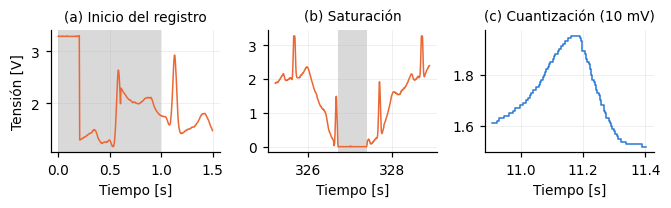

In [14]:
# --- Figura: detalles de los defectos del registro ---
# Tres paneles: (a) paquete viejo al inicio, (b) saturación, (c) cuantización.

# Se buscan los registros por condición (next devuelve el primero que cumple)
post = next(r for r in registros if r.condicion == "post_ejercicio")
repo = next(r for r in registros if r.condicion == "reposo")

fig, axs = plt.subplots(1, 3, figsize=(16/2.54, 5/2.54))

# (a) Primeros 1,5 s del registro post ejercicio. Se sombrea la zona que
#     mascara_valida() descarta (DESCARTE_INICIO).
n = int(1.5 * post.fs); t = np.arange(n) / post.fs
axs[0].plot(t, post.ecg[:n], **graficos.estilo_registro(post.voluntario, post.condicion))
axs[0].axvspan(0, acond.DESCARTE_INICIO, color="0.85", lw=0)   # franja gris
axs[0].set(title="(a) Inicio del registro", xlabel="Tiempo [s]", ylabel="Tensión [V]")

# (b) El tramo saturado más largo del post ejercicio, con 1,5 s a cada lado.
#     max(..., key=...) elige el tramo con mayor fin - inicio.
i0, i1 = max(acond.tramos_saturados(post.ecg, post.fs), key=lambda tr: tr[1] - tr[0])
m = int(1.5 * post.fs); a, b = max(i0 - m, 0), min(i1 + m, len(post.ecg))
t = np.arange(a, b) / post.fs
axs[1].plot(t, post.ecg[a:b], **graficos.estilo_registro(post.voluntario, post.condicion))
axs[1].axvspan(i0 / post.fs, i1 / post.fs, color="0.85", lw=0)   # el tramo saturado
axs[1].set(title="(b) Saturación", xlabel="Tiempo [s]")

# (c) Una onda T del registro en reposo, para ver los escalones de 10 mV.
#     Se busca el pico R más alto entre 10 y 12 s y se grafica de 0,15 a 0,65 s
#     después (donde está la onda T). step() dibuja escalones en vez de unir
#     los puntos con rectas, así se ve la cuantización tal cual es.
r = int(10 * repo.fs) + np.argmax(repo.ecg[int(10 * repo.fs):int(12 * repo.fs)])
a, b = r + int(0.15 * repo.fs), r + int(0.65 * repo.fs)
t = np.arange(a, b) / repo.fs
axs[2].step(t, repo.ecg[a:b], where="mid", **graficos.estilo_registro(repo.voluntario, repo.condicion))
axs[2].set(title="(c) Cuantización (10 mV)", xlabel="Tiempo [s]")

# Sin leyendas: los títulos ya dicen qué es cada panel
for ax in axs: ax.legend().remove() if ax.get_legend() else None
fig.tight_layout()
graficos.guardar_figura(fig, "acond_detalles")

V1_reposo            DEP(50 Hz) / DEP(vecinas) = 0.80
V1_post_ejercicio    DEP(50 Hz) / DEP(vecinas) = 0.65


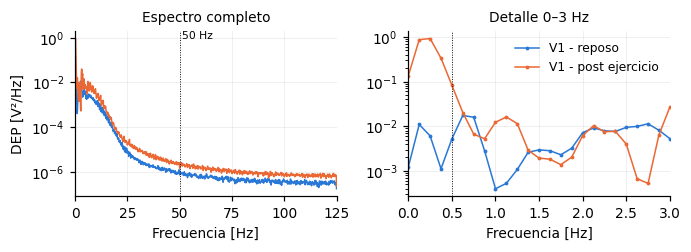

In [15]:
# --- Figura: espectro de los registros crudos ---
# Izquierda: espectro completo, para buscar el pico de 50 Hz (red eléctrica).
# Derecha: zoom de 0 a 3 Hz, para ver la deriva de la línea de base.

fig, axs = plt.subplots(1, 2, figsize=(16/2.54, 6/2.54))
for reg in registros:
    # Densidad espectral de potencia por Welch (ver acond.espectro)
    f, p = acond.espectro(reg.ecg, reg.fs)
    # semilogy: eje y logarítmico, porque la potencia varía en muchos órdenes
    axs[0].semilogy(f, p, **graficos.estilo_registro(reg.voluntario, reg.condicion))
    # Para el zoom se grafican sólo las frecuencias hasta 3 Hz, así el eje y
    # se ajusta a ese rango. marker="." muestra cada punto de frecuencia.
    b = f <= 3
    axs[1].semilogy(f[b], p[b], marker=".", ms=3, **graficos.estilo_registro(reg.voluntario, reg.condicion))
axs[0].axvline(acond.F_RED, color="k", lw=0.6, ls=":")   # línea en 50 Hz
axs[0].text(acond.F_RED + 1, axs[0].get_ylim()[1], "50 Hz", va="top", fontsize=7)
axs[0].set(xlabel="Frecuencia [Hz]", ylabel="DEP [V²/Hz]", title="Espectro completo", xlim=(0, f[-1]))
axs[1].axvline(acond.FC_PASAALTOS, color="k", lw=0.6, ls=":")   # corte del pasaaltos
axs[1].set(xlabel="Frecuencia [Hz]", title="Detalle 0–3 Hz", xlim=(0, 3))
axs[1].legend()
fig.tight_layout()
graficos.guardar_figura(fig, "acond_espectro_crudo")

# ¿Hay pico en 50 Hz? Se compara la potencia en 50 Hz con la mediana de las
# frecuencias vecinas (entre 2 y 8 Hz de distancia). Si hubiera interferencia
# de red, el cociente sería mucho mayor que 1. Da ≈ 1 o menos: no hay pico.
for reg in registros:
    f, p = acond.espectro(reg.ecg, reg.fs)
    en_50 = p[np.argmin(abs(f - 50))]   # el punto de frecuencia más cercano a 50 Hz
    vecinas = np.median(p[(abs(f - 50) > 2) & (abs(f - 50) < 8)])
    print(f"{reg.nombre:20s} DEP(50 Hz) / DEP(vecinas) = {en_50 / vecinas:.2f}")

In [16]:
# --- Tabla: saturación y fracción válida de cada registro ---
# Una fila por registro, con los números de acond.resumen_calidad():
#   saturadas_%         % de muestras en los extremos (incluye puntas de R recortadas)
#   tramos_largos       cuántos tramos saturados de >= 0,1 s hay (los que se interpolan)
#   s_en_tramos_largos  cuántos segundos suman esos tramos
#   valida_%            % de la señal que queda para el análisis (mascara_valida)
# .T traspone para que cada registro sea una fila; .round(2) redondea.
pd.DataFrame({reg.nombre: acond.resumen_calidad(reg.ecg, reg.fs) for reg in registros}).T.round(2)

,saturadas_%,tramos_largos,s_en_tramos_largos,valida_%
V1_reposo,0.06,0.0,0.00,99.13
V1_post_ejercicio,1.64,10.0,3.24,98.10


**Qué muestran las figuras**

- **Nivel de continua**: los dos registros están montados sobre ~1,65 V.
- **Deriva de la línea de base**: leve en reposo; en post ejercicio es de más de 1 V, con potencia concentrada por debajo de 0,5 Hz.
- **Saturación**: el registro de reposo no satura. El post ejercicio toca 0 V y 3,3 V: las puntas de muchas ondas R quedan recortadas en 3,3 V (pocas muestras) y la deriva lleva la línea de base a 0 V en varios tramos de hasta ~0,7 s.
- **Inicio**: el registro post ejercicio empieza con ~0,2 s saturados y un salto, el paquete viejo de la interfaz.
- **Cuantización**: escalones de 10 mV, visibles en la onda T.
- **50 Hz**: no hay pico; la relación DEP(50 Hz)/vecinas es ≈ 1. No hace falta notch.

## Ítem 5 — Acondicionamiento

Etapas (en `acondicionamiento.py`), en este orden:

1. **Interpolación de tramos saturados largos** (≥ 0,1 s): se reemplazan por una recta para que el filtro no oscile. Las puntas de R recortadas no se tocan.
2. **Resta de la mediana**: quita el nivel de continua de 1,65 V.
3. **Pasaaltos Butterworth de 0,5 Hz con fase cero** (`sosfiltfilt`): quita la deriva de la línea de base sin correr los picos.

Aparte, `mascara_valida()` marca el primer segundo y los tramos saturados largos (con 0,2 s de margen) para que M2/M3 descarten esos latidos. No se borran muestras de la señal, para que conserve su longitud.

Las celdas siguientes muestran los parámetros, comprueban que la salida cumple lo que pide el README y generan las figuras del antes/después.

In [17]:
# --- Parámetros usados (para la tabla del informe) ---
# Se leen directamente de acondicionamiento.py, así lo que se imprime siempre
# coincide con lo que realmente se aplicó.
print(f"Interpolación de saturaciones: tramos ≥ {acond.DURACION_SAT_MIN} s, tolerancia {100*acond.TOLERANCIA_SAT:.0f} % del rango")
print(f"Pasaaltos: Butterworth orden {acond.ORDEN_PASAALTOS} (×2 con filtfilt), fc = {acond.FC_PASAALTOS} Hz")
print(f"Notch 50 Hz: {'sí' if acond.APLICAR_NOTCH else 'no'}")
print(f"Máscara: primeros {acond.DESCARTE_INICIO} s, margen {acond.MARGEN_SAT} s alrededor de cada saturación")

# --- Comprobaciones que pide el README: misma longitud y sin corrimiento ---
from scipy.signal import find_peaks
for reg in registros:
    y = acond.acondicionar(reg.ecg, reg.fs)
    # 1) La salida tiene que tener la misma cantidad de muestras (si no, error)
    assert y.shape == reg.ecg.shape

    # 2) Los picos no se tienen que correr. Se buscan los picos de la señal
    #    CRUDA (separados al menos 0,3 s y que sobresalgan 0,5 V) y, para cada
    #    uno, dónde está el máximo de la señal ACONDICIONADA en una ventana de
    #    ±30 ms. La diferencia entre las dos posiciones es el corrimiento.
    picos, _ = find_peaks(reg.ecg, distance=int(0.3 * reg.fs), prominence=0.5)
    v = int(0.03 * reg.fs)   # medio ancho de la ventana, en muestras
    corr = [p - v + np.argmax(y[p - v:p + v]) - p for p in picos if v <= p < len(y) - v]
    print(f"{reg.nombre:20s} misma longitud: sí   corrimiento de picos R: máx {max(map(abs, corr))} muestras "
          f"(mediana {np.median(np.abs(corr)):.0f}) en {len(corr)} picos")

Interpolación de saturaciones: tramos ≥ 0.1 s, tolerancia 1 % del rango
Pasaaltos: Butterworth orden 2 (×2 con filtfilt), fc = 0.5 Hz
Notch 50 Hz: no
Máscara: primeros 1.0 s, margen 0.2 s alrededor de cada saturación
V1_reposo            misma longitud: sí   corrimiento de picos R: máx 2 muestras (mediana 0) en 81 picos
V1_post_ejercicio    misma longitud: sí   corrimiento de picos R: máx 6 muestras (mediana 0) en 486 picos


WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/Trabajos Practicos/Informe-Laboratorio-ECG---PSIB---Grupo-2-/informe/figuras/acond_antes_despues.pdf')

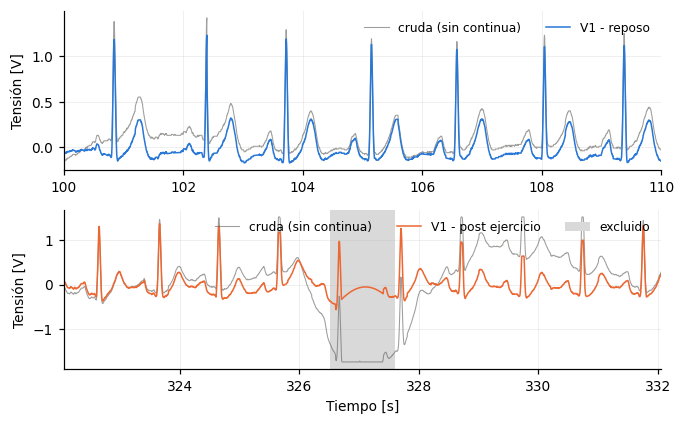

In [18]:
# --- Figura: antes / después del acondicionamiento ---
# 10 s de cada registro: cruda (gris) y acondicionada (color), con los tramos
# que excluye mascara_valida() sombreados.
# En reposo se muestra un tramo cualquiera (desde 100 s); en post ejercicio,
# el tramo centrado en la saturación más larga, para que se vea la interpolación.
DUR = 10   # s
fig, axs = plt.subplots(len(registros), 1, figsize=(16/2.54, 5*len(registros)/2.54))
axs = np.atleast_1d(axs)
for ax, reg in zip(axs, registros):
    y = acond.acondicionar(reg.ecg, reg.fs)          # señal acondicionada
    valida = acond.mascara_valida(reg.ecg, reg.fs)   # True/False por muestra
    tramos = acond.tramos_saturados(reg.ecg, reg.fs)

    # Inicio de la ventana: centrada en el tramo saturado más largo, si hay
    if tramos:
        i0, i1 = max(tramos, key=lambda tr: tr[1] - tr[0])
        T0 = (i0 + i1) / 2 / reg.fs - DUR / 2
    else:
        T0 = 100

    t = np.arange(len(y)) / reg.fs
    m = (t >= T0) & (t < T0 + DUR)   # máscara de las muestras dentro de la ventana

    # Cruda sin la continua (restando la mediana), para poder compararla en la
    # misma escala que la acondicionada
    ax.plot(t[m], reg.ecg[m] - np.median(reg.ecg), color=graficos.COLOR_NEUTRO, lw=0.7,
            alpha=0.6, label="cruda (sin continua)")
    ax.plot(t[m], y[m], **graficos.estilo_registro(reg.voluntario, reg.condicion))

    # Sombreado gris donde la máscara vale False. Con get_xaxis_transform(),
    # el 0 y el 1 de fill_between son el borde inferior y superior del gráfico.
    if (~valida[m]).any():
        ax.fill_between(t[m], 0, 1, where=~valida[m], color="0.85", lw=0,
                        transform=ax.get_xaxis_transform(), label="excluido")
    ax.set(ylabel="Tensión [V]", xlim=(T0, T0 + DUR))
    ax.legend(loc="upper right", ncol=3)
axs[-1].set_xlabel("Tiempo [s]")
fig.tight_layout()
graficos.guardar_figura(fig, "acond_antes_despues")

WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/Trabajos Practicos/Informe-Laboratorio-ECG---PSIB---Grupo-2-/informe/figuras/acond_espectro_antes_despues.pdf')

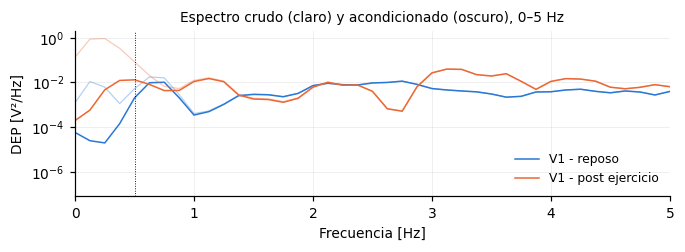

In [19]:
# --- Figura: espectro antes / después ---
# Crudo en trazo claro y acondicionado en trazo oscuro, de 0 a 5 Hz.
# Debajo de 0,5 Hz (línea punteada) la potencia tiene que caer: es la deriva
# que quita el pasaaltos. Por encima de ~1 Hz las dos curvas deberían coincidir,
# lo que muestra que el filtro no toca la banda del ECG.
fig, ax = plt.subplots(figsize=(16/2.54, 6/2.54))
for reg in registros:
    est = graficos.estilo_registro(reg.voluntario, reg.condicion)
    # crudo: mismo color, transparente y sin etiqueta
    f, p = acond.espectro(reg.ecg, reg.fs)
    ax.semilogy(f, p, color=est["color"], lw=0.8, ls=est["linestyle"], alpha=0.35)
    # acondicionado: trazo normal, con etiqueta para la leyenda
    f, p = acond.espectro(acond.acondicionar(reg.ecg, reg.fs), reg.fs)
    ax.semilogy(f, p, **est)
ax.axvline(acond.FC_PASAALTOS, color="k", lw=0.6, ls=":")
ax.set(xlabel="Frecuencia [Hz]", ylabel="DEP [V²/Hz]", xlim=(0, 5),
       title="Espectro crudo (claro) y acondicionado (oscuro), 0–5 Hz")
ax.legend()
fig.tight_layout()
graficos.guardar_figura(fig, "acond_espectro_antes_despues")